## Import Libraries

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
import config

## Functions

In [2]:
def fit_factor_attribution(data):
    # Estimate the six-factor model with Newey-West standard errors
    X = sm.add_constant(data[FACTOR_COLUMNS], has_constant="add")
    model = sm.OLS(data["Excess_Return"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})

    # Annualize the intercept and its confidence interval
    alpha = model.params["const"] * 252 * 100
    alpha_interval = model.conf_int().loc["const"] * 252 * 100

    # Regression coefficients and diagnostics
    results = {
        "Start_Date": data["Date"].min().date(),
        "End_Date": data["Date"].max().date(),
        "Observations": int(model.nobs),
        "Annualized_Alpha_Pct": alpha,
        "Alpha_t_stat": model.tvalues["const"],
        "Alpha_p_value": model.pvalues["const"],
        "Alpha_CI_Lower_Pct": alpha_interval.iloc[0],
        "Alpha_CI_Upper_Pct": alpha_interval.iloc[1],
        "R_Squared": model.rsquared,
        **{
            f"Beta_{FACTOR_LABELS[factor]}": model.params[factor]
            for factor in FACTOR_COLUMNS
        },
    }

    # Decompose annualized arithmetic excess returns
    attribution = {
        "Alpha_Pct": alpha,
        **{
            f"{FACTOR_LABELS[factor]}_Pct": (
                model.params[factor] * data[factor].mean() * 252 * 100
            )
            for factor in FACTOR_COLUMNS
        },
        "Annualized_Excess_Return_Pct": (
            data["Excess_Return"].mean() * 252 * 100
        ),
    }

    return results, attribution

## Load Configuration and Factor Data

In [3]:
# Input and output directories
FACTOR_DIR = config.INPUT_DATA_DIR / "fama_french"
PORTFOLIO_DIR = config.OUTPUT_DIR / "portfolio_results"
OUTPUT = config.OUTPUT_DIR / "return_attribution"

# Six-factor model
FACTOR_COLUMNS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]

FACTOR_LABELS = {
    "Mkt-RF": "Market",
    "SMB": "SMB",
    "HML": "HML",
    "RMW": "RMW",
    "CMA": "CMA",
    "Mom": "Momentum",
}

# Selected strategy and benchmarks
STRATEGY_LABELS = {
    "Hybrid_50_XGB_EW_50_Full_Regime_Aware_LW": "XGB 50/50 Hybrid",
    "Full_Universe_Optimized_Regime_Aware_LW": "Full Universe",
    "SPY_Buy_Hold": "SPY",
}

# Read daily Fama-French factors
ff5 = pd.read_csv(FACTOR_DIR / "Fama_French_5_Factors_Daily.csv", parse_dates=["Date"])
momentum = pd.read_csv(FACTOR_DIR / "Momentum_Factor_Daily.csv", parse_dates=["Date"])

# Match factor observations by trading date
factors = (ff5.merge(momentum, on="Date", validate="one_to_one").sort_values("Date").reset_index(drop=True))

# Convert percentages to decimal returns
factor_return_columns = FACTOR_COLUMNS + ["RF"]
factors[factor_return_columns] = (factors[factor_return_columns].apply(pd.to_numeric, errors="raise") / 100)

print(f"Factor coverage: {factors['Date'].min().date()} to {factors['Date'].max().date()}")

Factor coverage: 1963-07-01 to 2026-09-30


## Load Portfolio Returns

In [4]:
# Portfolio NAV exports from S05
NAV_FILES = {
    "Validation": PORTFOLIO_DIR / "validation_portfolio_daily_nav.csv",
    "Test": PORTFOLIO_DIR / "test_portfolio_daily_nav.csv",
}

nav_parts = []

for period, file_path in NAV_FILES.items():
    nav = pd.read_csv(file_path, parse_dates=["Date"])

    # Check availability of the three strategies
    missing = set(STRATEGY_LABELS) - set(nav["Strategy"])

    if missing:
        raise ValueError(f"{period}: missing strategies: {sorted(missing)}")

    # Retain daily net portfolio returns
    nav = nav.loc[nav["Strategy"].isin(STRATEGY_LABELS), ["Date", "Strategy", "Daily_Return"],].copy()
    nav["Period"] = period
    nav_parts.append(nav)

portfolio_returns = pd.concat(nav_parts, ignore_index=True)

# Align portfolio and factor returns by date
aligned_returns = portfolio_returns.merge(factors, on="Date", how="inner", validate="many_to_one", )
aligned_returns = aligned_returns.dropna(subset=["Daily_Return", "RF"] + FACTOR_COLUMNS).copy()

# Calculate daily excess portfolio returns
aligned_returns["Excess_Return"] = (aligned_returns["Daily_Return"] - aligned_returns["RF"])

# Show effective regression coverage
coverage = (aligned_returns.groupby(["Period", "Strategy"])["Date"].agg(["min", "max", "count"]).reset_index())

coverage["Strategy"] = coverage["Strategy"].replace(STRATEGY_LABELS)
display(coverage)

,Period,Strategy,min,max,count
0,Test,Full Universe,2022-01-04,2026-09-30,1189
1,Test,XGB 50/50 Hybrid,2022-01-04,2026-09-30,1189
2,Test,SPY,2022-01-04,2026-09-30,1189
3,Validation,Full Universe,2016-01-21,2021-10-07,1440
4,Validation,XGB 50/50 Hybrid,2016-01-21,2021-10-07,1440
5,Validation,SPY,2016-01-21,2021-10-07,1440


## Return Attribution

In [5]:
# Estimate separate validation and test regressions
regression_parts = []
attribution_parts = []

for (period, strategy), data in aligned_returns.groupby(["Period", "Strategy"], sort=False):
    results, attribution = fit_factor_attribution(data)

    regression_parts.append({
        "Period": period,
        "Strategy": STRATEGY_LABELS[strategy],
        **results,
    })

    attribution_parts.append({
        "Period": period,
        "Strategy": STRATEGY_LABELS[strategy],
        **attribution,
    })

regression_results = pd.DataFrame(regression_parts)
attribution_results = pd.DataFrame(attribution_parts)

# Consistent period and strategy order
period_order = {"Validation": 0, "Test": 1}
strategy_order = {"XGB 50/50 Hybrid": 0, "Full Universe": 1, "SPY": 2, }

for frame in [regression_results, attribution_results]:
    frame["_period_order"] = frame["Period"].map(period_order)
    frame["_strategy_order"] = frame["Strategy"].map(strategy_order)
    frame.sort_values(["_period_order", "_strategy_order"], inplace=True, )
    frame.drop(columns=["_period_order", "_strategy_order"], inplace=True, )
    frame.reset_index(drop=True, inplace=True)

## Evaluation

Factor Exposures:


,Period,Strategy,Observations,Annualized_Alpha_Pct,Alpha_t_stat,Alpha_p_value,Beta_Market,Beta_SMB,Beta_HML,Beta_RMW,Beta_CMA,Beta_Momentum,R_Squared
0,Validation,XGB 50/50 Hybrid,1440,10.9425,1.9692,0.0489,0.6673,0.1677,0.0182,-0.1199,0.0949,0.2106,0.5704
1,Validation,Full Universe,1440,18.7244,2.0373,0.0416,0.8095,0.2930,-0.0021,-0.2428,0.1094,0.3887,0.4314
2,Validation,SPY,1440,-0.5200,-1.2826,0.1996,0.9742,-0.1110,0.0176,0.0614,0.0329,-0.0135,0.9955
3,Test,XGB 50/50 Hybrid,1189,4.7808,1.2092,0.2266,0.4563,0.0865,0.0008,-0.2663,0.1213,0.2612,0.5649
4,Test,Full Universe,1189,6.5097,1.0109,0.3121,0.6418,0.0558,0.0384,-0.4934,0.0886,0.4271,0.5142
5,Test,SPY,1189,-0.1669,-0.3668,0.7138,0.9973,-0.0880,0.0070,0.0418,0.0378,0.0060,0.9942


Factor Returns:


,Period,Strategy,Alpha_Pct,Market_Pct,SMB_Pct,HML_Pct,RMW_Pct,CMA_Pct,Momentum_Pct,Annualized_Excess_Return_Pct
0,Validation,XGB 50/50 Hybrid,10.943,12.400,0.225,-0.072,-0.245,-0.141,-0.882,22.227
1,Validation,Full Universe,18.724,15.042,0.394,0.008,-0.497,-0.163,-1.629,31.880
2,Validation,SPY,-0.520,18.102,-0.149,-0.069,0.126,-0.049,0.057,17.498
3,Test,XGB 50/50 Hybrid,4.781,3.853,-0.377,0.004,0.405,0.031,2.582,11.280
4,Test,Full Universe,6.510,5.421,-0.243,0.180,0.751,0.023,4.222,16.864
5,Test,SPY,-0.167,8.423,0.383,0.033,-0.064,0.010,0.060,8.679


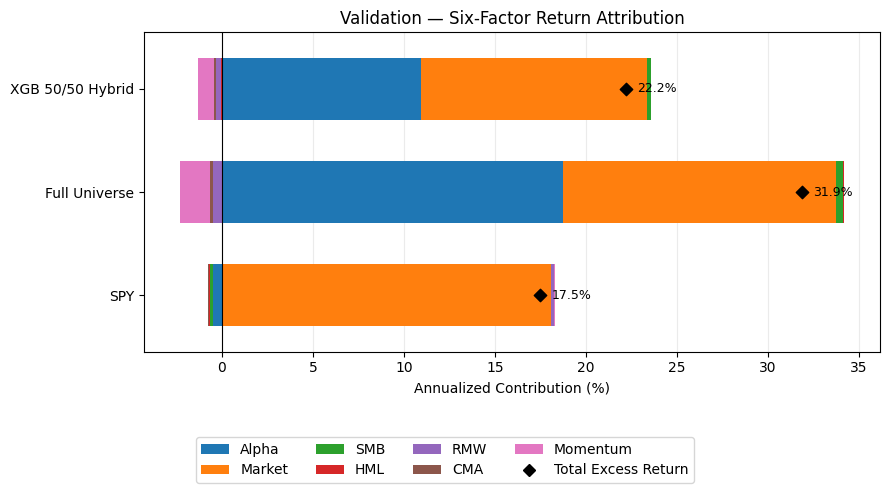

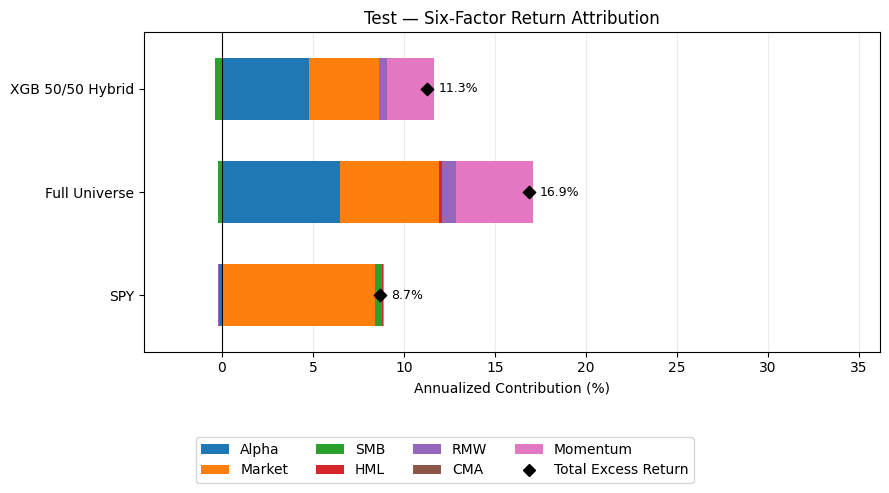

In [10]:
# Regression results
regression_columns = [
    "Period",
    "Strategy",
    "Observations",
    "Annualized_Alpha_Pct",
    "Alpha_t_stat",
    "Alpha_p_value",
    "Beta_Market",
    "Beta_SMB",
    "Beta_HML",
    "Beta_RMW",
    "Beta_CMA",
    "Beta_Momentum",
    "R_Squared",
]

print("Factor Exposures:")
display(regression_results[regression_columns].round(4))

# Annualized factor return attribution
print("Factor Returns:")
display(attribution_results.round(3))

# Factor contributions and display order
contribution_columns = {
    "Alpha_Pct": "Alpha",
    "Market_Pct": "Market",
    "SMB_Pct": "SMB",
    "HML_Pct": "HML",
    "RMW_Pct": "RMW",
    "CMA_Pct": "CMA",
    "Momentum_Pct": "Momentum",
}

strategy_order = ["XGB 50/50 Hybrid", "Full Universe", "SPY"]

# Consistent factor colors
factor_colors = {
    "Alpha": "#1f77b4",
    "Market": "#ff7f0e",
    "SMB": "#2ca02c",
    "HML": "#d62728",
    "RMW": "#9467bd",
    "CMA": "#8c564b",
    "Momentum": "#e377c2",
}

# Calculate common x-axis limits for both periods
all_contributions = attribution_results[list(contribution_columns)]

positive_sums = all_contributions.clip(lower=0).sum(axis=1)
negative_sums = all_contributions.clip(upper=0).sum(axis=1)

x_min = negative_sums.min() - 2
x_max = positive_sums.max() + 2

# Create separate horizontal stacked bar charts
for period in ["Validation", "Test"]:

    data = (
        attribution_results.loc[
            attribution_results["Period"].eq(period)
        ]
        .set_index("Strategy")
        .reindex(strategy_order)
    )

    contributions = data[list(contribution_columns)].rename(columns=contribution_columns)

    fig, ax = plt.subplots(figsize=(9, 5))

    # Plot positive and negative factor contributions
    contributions.plot(
        kind="barh",
        stacked=True,
        ax=ax,
        width=0.6,
        color=list(factor_colors.values()),
        legend=False,
    )

    # Add total annualized excess return markers
    total_returns = data["Annualized_Excess_Return_Pct"]

    ax.scatter(
        total_returns,
        range(len(total_returns)),
        color="black",
        marker="D",
        s=40,
        zorder=5,
        label="Total Excess Return",
    )

    # Label total excess returns
    for i, value in enumerate(total_returns):
        ax.annotate(
            f"{value:.1f}%",
            (value, i),
            xytext=(8 if value >= 0 else -8, 0),
            textcoords="offset points",
            ha="left" if value >= 0 else "right",
            va="center",
            fontsize=9,
        )

    # Format chart
    ax.set(
        title=f"{period} — Six-Factor Return Attribution",
        xlabel="Annualized Contribution (%)",
        ylabel="",
        xlim=(x_min, x_max),
    )

    ax.set_yticklabels(strategy_order, rotation=0)
    ax.invert_yaxis()
    ax.axvline(0, color="black", linewidth=0.8)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    # Add shared factor legend
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D

    legend_handles = [Patch(facecolor=color, label=factor) for factor, color in factor_colors.items()]

    legend_handles.append(
        Line2D(
            [0], [0],
            marker="D",
            color="black",
            linestyle="None",
            markersize=6,
            label="Total Excess Return",
        )
    )

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, 0.01),
    )

    fig.tight_layout(rect=[0, 0.17, 1, 1])
    plt.show()

## Export Results

In [7]:
# Export regression and return attribution results
OUTPUT.mkdir(parents=True, exist_ok=True)
regression_results.to_csv(OUTPUT / "factor_regression_results.csv", index=False, )
attribution_results.to_csv(OUTPUT / "factor_return_attribution.csv", index=False, )

print(f"Return attribution results saved to {OUTPUT}")

Return attribution results saved to C:\Users\enese\PyCharmMiscProject\MScFE_notebooks\Capstone_Project\capstone\output\2026-11-10\return_attribution
